# AI Programming Foundations: Titanic Data Workflow

**Author: AI Foundations (Edward Hickman)**  
**Dataset: Titanic (Seaborn example-data version)**

This project builds a reproducible descriptive workflow for Titanic passenger
records. It audits and cleans the data, explores recorded survival patterns across
passenger groups, and communicates findings through three visualizations.
No machine-learning models are trained.

**Research question:** How do recorded survival rates vary across passenger class
and sex, and what does age missingness imply for interpreting the age distribution?

The local CSV contains 891 observations and 15 columns, exceeding the rubric's
200-row/five-column minimum. These records are not a complete census of everyone
aboard the ship. Formal methodological citations and extended reasoning belong
in the separate written report; the source snapshot is documented below.

## 1. Imports, local paths, and reproducibility

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import platform
import importlib.metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from IPython.display import display

ROOT = Path.cwd().resolve()
assert (ROOT / "titanic.csv").exists(), "Run from the repository directory."
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False,
                     "axes.spines.right": False})
versions = {p: importlib.metadata.version(p)
            for p in ["numpy", "pandas", "matplotlib", "seaborn"]}
print("Python", platform.python_version())
print(json.dumps(versions, indent=2))

Python 3.11.18
{
  "numpy": "2.4.6",
  "pandas": "3.1.1",
  "matplotlib": "3.11.2",
  "seaborn": "0.13.2"
}


## 2. Ingestion and provenance

The CSV is beside the notebook and is not changed by this workflow.
Source: [Seaborn Titanic CSV, fixed revision](https://github.com/mwaskom/seaborn-data/blob/a29a0141d20e156043ec257a64c8de3b3a03fd6e/titanic.csv).
The SHA-256 check establishes that the input matches the reviewed snapshot.

In [2]:
source_hash = hashlib.sha256((ROOT / "titanic.csv").read_bytes()).hexdigest()
assert source_hash == "81787d320d7f7b03df935e91de8bd19e11d45c5bbcab86ef4d4a76dc91b7d4f2"
raw = pd.read_csv(ROOT / "titanic.csv")
assert raw.shape == (891, 15)
print("Rows, columns:", raw.shape)
print("Source SHA-256:", source_hash)
display(raw.head())

Rows, columns: (891, 15)
Source SHA-256: 81787d320d7f7b03df935e91de8bd19e11d45c5bbcab86ef4d4a76dc91b7d4f2


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 3. Audit before cleaning

Inspect types, missing values, and repeated attribute combinations before making
changes. A row that repeats all fifteen attributes need not be a duplicate person:
this dataset has no passenger ID. We retain every record rather than assume that
matching attributes identify the same person.

In [3]:
audit = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing_count": raw.isna().sum(),
    "missing_percent": raw.isna().mean().mul(100),
    "unique_observed_values": raw.nunique(dropna=True),
})
display(audit)
print("Repeated full-row combinations after the first:", int(raw.duplicated().sum()))
display(raw[["age", "fare", "sibsp", "parch"]].describe())
audit.to_csv(OUT / "raw_data_audit.csv")

,dtype,missing_count,missing_percent,unique_observed_values
survived,int64,0,0.000000,2
pclass,int64,0,0.000000,3
sex,str,0,0.000000,2
age,float64,177,19.865320,88
sibsp,int64,0,0.000000,7
parch,int64,0,0.000000,7
fare,float64,0,0.000000,248
embarked,str,2,0.224467,3
class,str,0,0.000000,3
who,str,0,0.000000,3


Repeated full-row combinations after the first: 107


,age,fare,sibsp,parch
count,714.000000,891.000000,891.000000,891.000000
mean,29.699118,32.204208,0.523008,0.381594
std,14.526497,49.693429,1.102743,0.806057
min,0.420000,0.000000,0.000000,0.000000
25%,20.125000,7.910400,0.000000,0.000000
50%,28.000000,14.454200,0.000000,0.000000
75%,38.000000,31.000000,1.000000,0.000000
max,80.000000,512.329200,8.000000,6.000000


## 4. Reusable cleaning functions

We define and apply three cleaning/transformation functions, each with a docstring.
Column and text normalization make the workflow reusable, even though this
well-structured source already has normalized names and observed labels.

For the research question, we select eight original fields and add an explicit
age-missing flag. We preserve missing ages rather than invent age observations.
Only Figure 1 excludes missing ages; Figures 2 and 3 use all 891 rows.
Missing embarkation labels become `unknown`, not the most frequent port.
This label does not recover the true port or remove potential missing-data bias.

In [4]:
def standardize_columns(frame):
    """Return a copy with trimmed, lowercase, underscore-separated column names."""
    result = frame.copy(deep=True)
    result.columns = (
        result.columns.str.strip().str.lower()
        .str.replace(r"\s+", "_", regex=True)
    )
    if result.columns.duplicated().any():
        raise ValueError("Column normalization produced duplicate names.")
    return result


def clean_categories(frame):
    """Normalize string labels and explicitly label missing embarkation as unknown."""
    result = frame.copy(deep=True)
    for column in result.columns:
        if pd.api.types.is_string_dtype(result[column]):
            result[column] = (
                result[column].astype("string").str.strip().str.lower()
                .replace("", pd.NA)
            )
    result["embarked"] = result["embarked"].fillna("unknown")
    return result


def prepare_analysis_data(frame):
    """Select the eight analysis fields, validate numeric values, and flag missing age."""
    columns = ["survived", "pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
    result = frame.loc[:, columns].copy()
    for column in ["survived", "pclass", "age", "sibsp", "parch", "fare"]:
        original_missing = result[column].isna()
        result[column] = pd.to_numeric(result[column], errors="coerce")
        if (result[column].isna() & ~original_missing).any():
            raise ValueError(f"Invalid numeric values in {column}.")
    if not result["survived"].isin([0, 1]).all():
        raise ValueError("Survived must be coded 0 or 1.")
    if not result["pclass"].isin([1, 2, 3]).all():
        raise ValueError("Passenger class must be 1, 2, or 3.")
    if (result[["age", "sibsp", "parch", "fare"]] < 0).any().any():
        raise ValueError("Age, family counts, and fare cannot be negative.")
    result["age_missing"] = result["age"].isna()
    return result

In [5]:
normalized = standardize_columns(raw)
categories_clean = clean_categories(normalized)
clean = prepare_analysis_data(categories_clean)
assert len(clean) == len(raw) == 891
assert clean["age"].isna().sum() == raw["age"].isna().sum()
assert clean["embarked"].isna().sum() == 0
pd.testing.assert_frame_equal(raw, pd.read_csv(ROOT / "titanic.csv"))

cleaning_log = {
    "raw_rows": len(raw), "raw_columns": raw.shape[1],
    "cleaned_rows": len(clean), "cleaned_columns": clean.shape[1],
    "renamed_columns": sum(a != b for a, b in zip(raw.columns, normalized.columns)),
    "missing_embarkation_labeled_unknown": int(raw["embarked"].isna().sum()),
    "missing_ages_preserved": int(clean["age_missing"].sum()),
    "repeated_full_row_combinations_retained": int(raw.duplicated().sum()),
    "rows_dropped": 0,
}
display(pd.Series(cleaning_log, name="cleaning_audit").to_frame())
display(clean.head())
clean.to_csv(OUT / "titanic_cleaned.csv", index=False)

,cleaning_audit
raw_rows,891
raw_columns,15
cleaned_rows,891
cleaned_columns,9
renamed_columns,0
missing_embarkation_labeled_unknown,2
missing_ages_preserved,177
repeated_full_row_combinations_retained,107
rows_dropped,0


,survived,pclass,sex,age,sibsp,parch,fare,embarked,age_missing
0,0,3,male,22.0,1,0,7.2500,s,False
1,1,1,female,38.0,1,0,71.2833,c,False
2,1,3,female,26.0,0,0,7.9250,s,False
3,1,1,female,35.0,1,0,53.1000,s,False
4,0,3,male,35.0,0,0,8.0500,s,False


## 5. Reusable exploratory analysis

The EDA function returns numerical summaries, group counts and observed survival
rates, and an age-missingness comparison. Rates are descriptive proportions for
these records, not causal effects or estimates for today's population.
We use NumPy to independently check the overall proportion.

In [6]:
def summarize_passengers(frame):
    """Return numerical, class, sex-by-class, and age-missingness summaries."""
    numeric = frame[["age", "fare", "sibsp", "parch"]].describe()
    by_class = frame.groupby("pclass", observed=True)["survived"].agg(
        passengers="size", survivors="sum", survival_rate="mean"
    )
    by_sex_class = frame.groupby(["pclass", "sex"], observed=True)["survived"].agg(
        passengers="size", survivors="sum", survival_rate="mean"
    )
    by_age_missing = frame.groupby("age_missing", observed=True)["survived"].agg(
        passengers="size", survivors="sum", survival_rate="mean"
    )
    return {"numeric": numeric, "by_class": by_class,
            "by_sex_class": by_sex_class, "by_age_missing": by_age_missing}

In [7]:
eda = summarize_passengers(clean)
for name, table in eda.items():
    print(name)
    display(table)
    table.to_csv(OUT / f"{name}.csv")
overall_survival = float(np.mean(clean["survived"].to_numpy()))
assert np.isclose(overall_survival, clean["survived"].mean())
print(f"Overall observed survival: {overall_survival:.2%}")

numeric


,age,fare,sibsp,parch
count,714.000000,891.000000,891.000000,891.000000
mean,29.699118,32.204208,0.523008,0.381594
std,14.526497,49.693429,1.102743,0.806057
min,0.420000,0.000000,0.000000,0.000000
25%,20.125000,7.910400,0.000000,0.000000
50%,28.000000,14.454200,0.000000,0.000000
75%,38.000000,31.000000,1.000000,0.000000
max,80.000000,512.329200,8.000000,6.000000


by_class


,passengers,survivors,survival_rate
pclass,,,
1,216,136,0.629630
2,184,87,0.472826
3,491,119,0.242363


by_sex_class


passengers  survivors  survival_rate
pclass sex                                         
1      female          94         91       0.968085
       male           122         45       0.368852
2      female          76         70       0.921053
       male           108         17       0.157407
3      female         144         72       0.500000
       male           347         47       0.135447

by_age_missing


,passengers,survivors,survival_rate
age_missing,,,
False,714,290,0.406162
True,177,52,0.293785


Overall observed survival: 38.38%


## 6. Figure 1 — Observed passenger ages

Purpose: show the shape of the recorded age distribution without filling in
unobserved ages. The title reports both the observed and excluded counts.
The histogram describes only passengers whose ages were recorded.

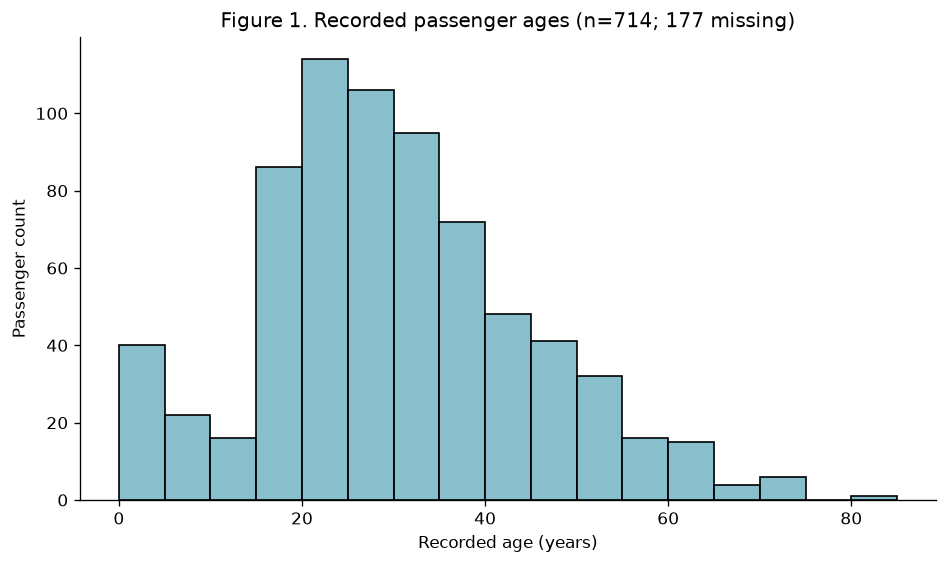

In [8]:
known_ages = clean["age"].dropna()
fig, ax = plt.subplots(figsize=(8, 4.8))
sns.histplot(known_ages, bins=np.arange(0, 86, 5), color="#61A9BD", ax=ax)
ax.set(
    title=f"Figure 1. Recorded passenger ages (n={len(known_ages)}; {clean['age_missing'].sum()} missing)",
    xlabel="Recorded age (years)", ylabel="Passenger count",
)
fig.tight_layout()
fig.savefig(OUT / "figure_1_age_distribution.png")
plt.show()

## 7. Figure 2 — Observed survival by passenger class

Purpose: compare descriptive survival proportions across the three recorded
passenger classes. Labels show each group's denominator. The common axis runs
from zero to 100%; no records are removed for missing age.

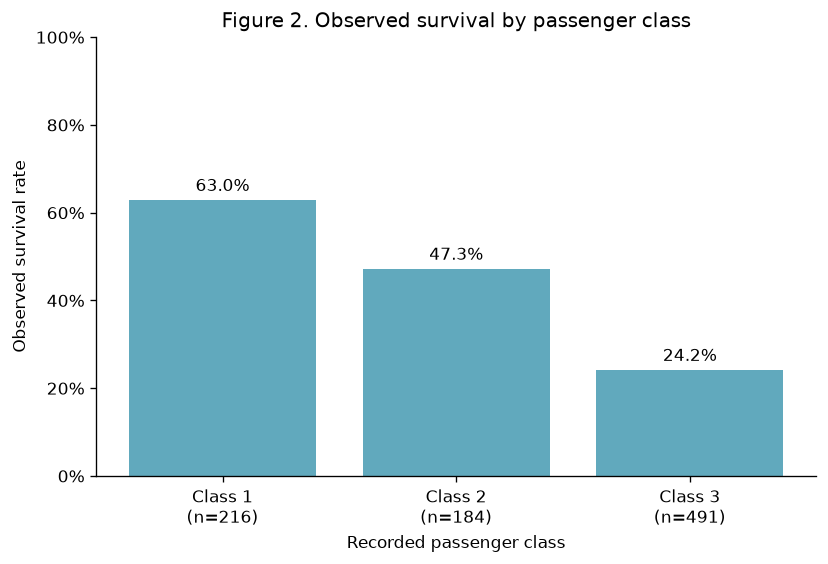

In [9]:
by_class = eda["by_class"]
fig, ax = plt.subplots(figsize=(7, 4.8))
bars = ax.bar(
    [f"Class {i}\n(n={row.passengers:.0f})" for i, row in by_class.iterrows()],
    by_class["survival_rate"], color="#61A9BD",
)
ax.set(title="Figure 2. Observed survival by passenger class",
       xlabel="Recorded passenger class", ylabel="Observed survival rate", ylim=(0, 1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
for bar, rate in zip(bars, by_class["survival_rate"]):
    ax.text(bar.get_x() + bar.get_width()/2, rate + .02, f"{rate:.1%}", ha="center")
fig.tight_layout()
fig.savefig(OUT / "figure_2_survival_by_class.png")
plt.show()

## 8. Figure 3 — Recorded sex and survival within passenger class

Purpose: check whether the class-only comparison hides differences between the
recorded female and male groups. Each bar reports its own sample size.
The source's historical binary sex labels are reproduced as recorded; they
do not measure gender identity. This is an association, not a causal explanation.

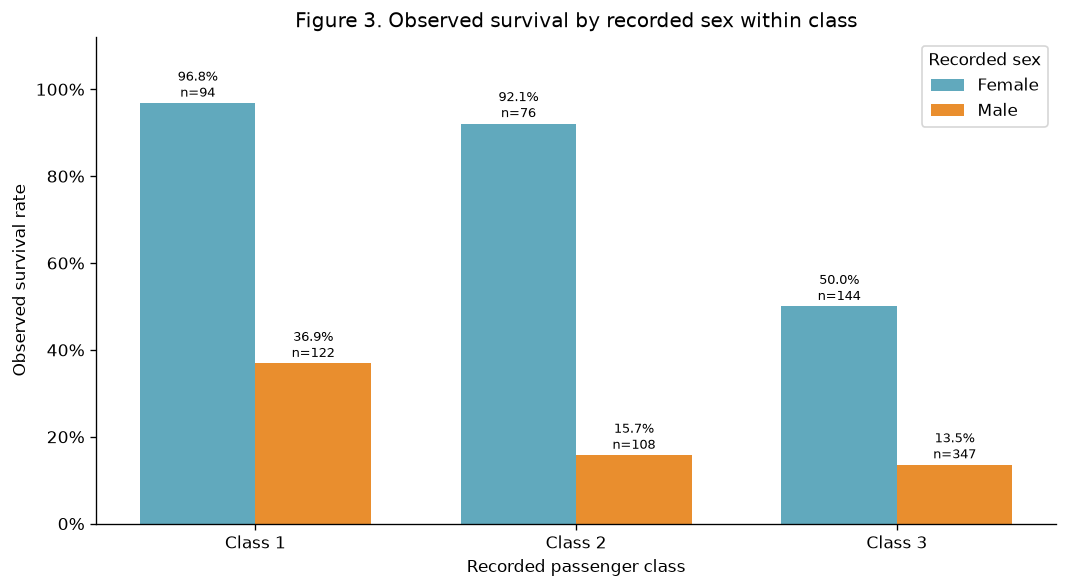

In [10]:
by_sex_class = eda["by_sex_class"]
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(3)
width = .36
for offset, sex, color in [(-width/2, "female", "#61A9BD"),
                           (width/2, "male", "#E98E2E")]:
    group = by_sex_class.xs(sex, level="sex").reindex([1, 2, 3])
    bars = ax.bar(x + offset, group["survival_rate"], width,
                  label=sex.capitalize(), color=color)
    for bar, (_, row) in zip(bars, group.iterrows()):
        ax.text(bar.get_x() + bar.get_width()/2, row.survival_rate + .015,
                f"{row.survival_rate:.1%}\nn={row.passengers:.0f}",
                ha="center", fontsize=8)
ax.set(title="Figure 3. Observed survival by recorded sex within class",
       xlabel="Recorded passenger class", ylabel="Observed survival rate", ylim=(0, 1.12))
ax.set_xticks(x, ["Class 1", "Class 2", "Class 3"])
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(title="Recorded sex", loc="upper right")
fig.tight_layout()
fig.savefig(OUT / "figure_3_survival_by_sex_class.png")
plt.show()

## 9. Save an evidence record

The following file supports the report and audit checks. It records observed
values, cleaning decisions, software versions, and source integrity, rather
than substituting hypothetical examples for actual results.

In [11]:
summary = {
    "author": "AI Foundations (Edward Hickman)", "source_sha256": source_hash,
    "python_version": platform.python_version(), "package_versions": versions,
    "cleaning": cleaning_log,
    "overall_survival_rate": overall_survival,
    "survivors": int(clean["survived"].sum()),
    "known_age_count": int(known_ages.size),
    "median_recorded_age": float(known_ages.median()),
    "age_missing_percent": float(clean["age_missing"].mean() * 100),
    "class_summary": by_class.reset_index().to_dict(orient="records"),
    "sex_class_summary": by_sex_class.reset_index().to_dict(orient="records"),
    "age_missing_summary": eda["by_age_missing"].reset_index().to_dict(orient="records"),
}
(OUT / "workflow_summary.json").write_text(json.dumps(summary, indent=2))
print("Saved audit tables, cleaned data, three figures, and workflow_summary.json.")
print("All raw input rows retained; source CSV remains unchanged.")

Saved audit tables, cleaned data, three figures, and workflow_summary.json.
All raw input rows retained; source CSV remains unchanged.


## 10. Summary and interpretation

Recorded survival is higher in first class than in second or third class
(Figure 2). The class totals are uneven, so comparing survivor counts alone
would not answer the research question; the plotted rates use the displayed
denominators. Within every class, the recorded female group has a higher
observed survival proportion than the recorded male group (Figure 3).
These descriptive differences do not demonstrate that sex or class alone
caused survival.

The observed age distribution is concentrated in younger adulthood, but 177
ages are missing (Figure 1). The age-missingness table shows different observed
survival proportions for records with and without ages, making a blanket
complete-case analysis questionable. This is a warning, not proof of a specific
missing-data mechanism. We preserved missing ages and retained these passengers
in the survival summaries rather than silently narrowing the dataset.

An important data-quality finding is that 107 full-row attribute combinations
repeat earlier records. Without passenger identifiers, these cannot be assumed
to be erroneous duplicate people, so we did not remove them. The CSV includes
redundant or derived fields, and the focused analysis selects eight original
fields plus an age-missingness flag rather than treating every column as
independent evidence.

Limitations include historical selection and recording practices, incomplete age
information, the absence of passenger IDs, the restricted binary sex labels, and
the fact that these 891 records are not a complete ship manifest. We cannot
identify the reasons for missing ages or reconstruct omitted contextual factors.
The workflow is a reproducible foundation for later AI work, not a trained model
or a causal study. The report discusses further methodological safeguards and
the use of agentic automation.